## IMPORTING MODULES

In [5]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import matplotlib.pyplot as plt

import torch
from torch import nn
from torch import optim
import torch.nn.functional as F
from torchvision import datasets, transforms, models
import glob 
import os 
import pandas as pd
import numpy as np
import random
from PIL import Image
import seaborn as sns

# LOAD DATA 

In [6]:
classes = {"cane": "dog", 
           "cavallo": "horse", 
           "elefante": "elephant", 
           "farfalla": "butterfly", 
           "gallina": "chicken", 
           "gatto": "cat", 
           "mucca": "cow", 
           "pecora": "sheep", 
           "scoiattolo": "squirrel", 
           "dog": "cane", 
           "cavallo": "horse", 
           "elephant" : "elefante",
           "butterfly": "farfalla", 
           "chicken": "gallina", "cat": "gatto",
           "cow": "mucca",
           "spider": "ragno",
           "squirrel": "scoiattolo"}

data = {
    'path': [],
    'label': [],
}

DATA_DIR = 'archive/raw-img'

# EXPLORE DATA 

In [7]:
for label_it, label_en in classes.items():
    paths = glob.glob(f'{DATA_DIR}/{label_it}/*.jpeg')
    
    data['path'].extend(paths)
    data['label'].extend([label_en] * len(paths))
    
df_data = pd.DataFrame(data)
df_data.head()

,path,label
0,archive/raw-img/cane/OIP-7Kyjub53-QqanyWanuJpO...,dog
1,archive/raw-img/cane/OIP-L3TRIOoPlmb3isOmx9DYD...,dog
2,archive/raw-img/cane/OIP-bTKnRAJfpOhQhD4AC4ZjZ...,dog
3,archive/raw-img/cane/OIP-nj_6eSbDiI1jXD7cPD4i7...,dog
4,archive/raw-img/cane/OIP-sH7u4NwO_gj427Z0cw3C5...,dog


In [8]:
df_data.label.unique()

array(['dog', 'horse', 'elephant', 'butterfly', 'chicken', 'cat', 'cow',
       'sheep', 'squirrel'], dtype=object)

### PLOTTING FEW IMAGES

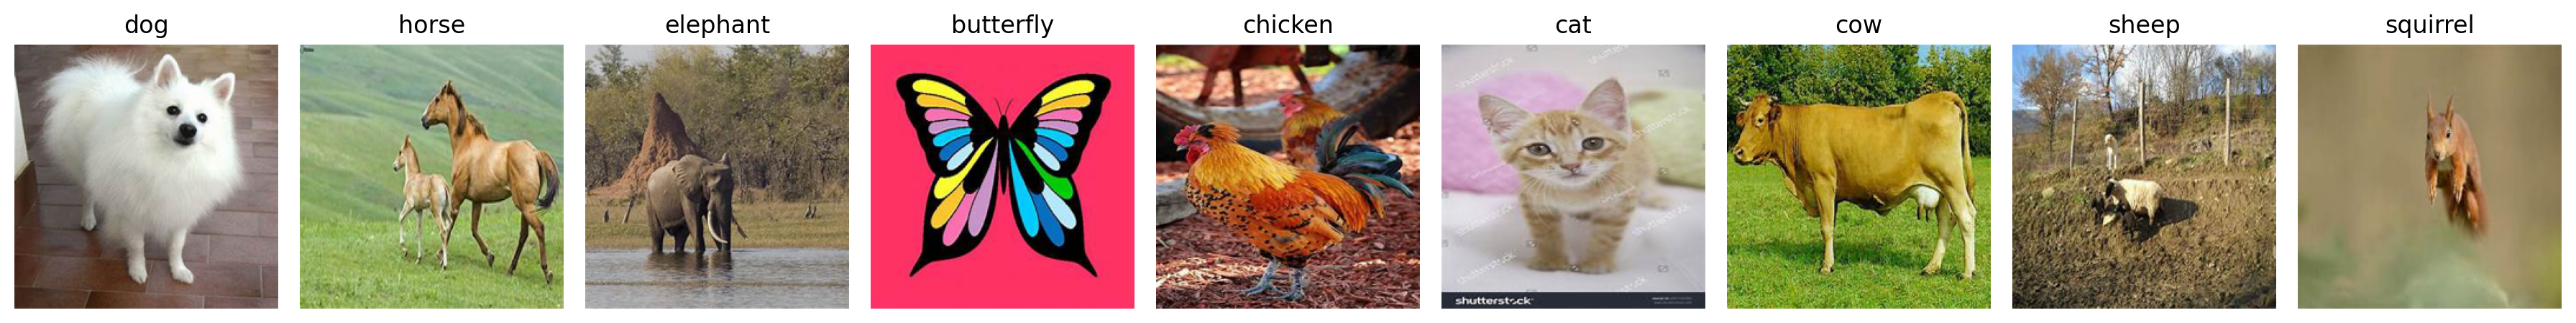

In [9]:
plt.figure(figsize = (20, 7))

for idx, i in enumerate(df_data.label.unique()):
    plt.subplot(1, 10, idx + 1)
    df = df_data[df_data['label'] == i].reset_index(drop=True)
    
    image_path = df.loc[random.randint(0, len(df) - 1), 'path']
    img = Image.open(image_path)
    img = img.resize((224, 224))
    plt.imshow(img)
    plt.axis('off')
    plt.title(i)
    
plt.tight_layout()
plt.show()

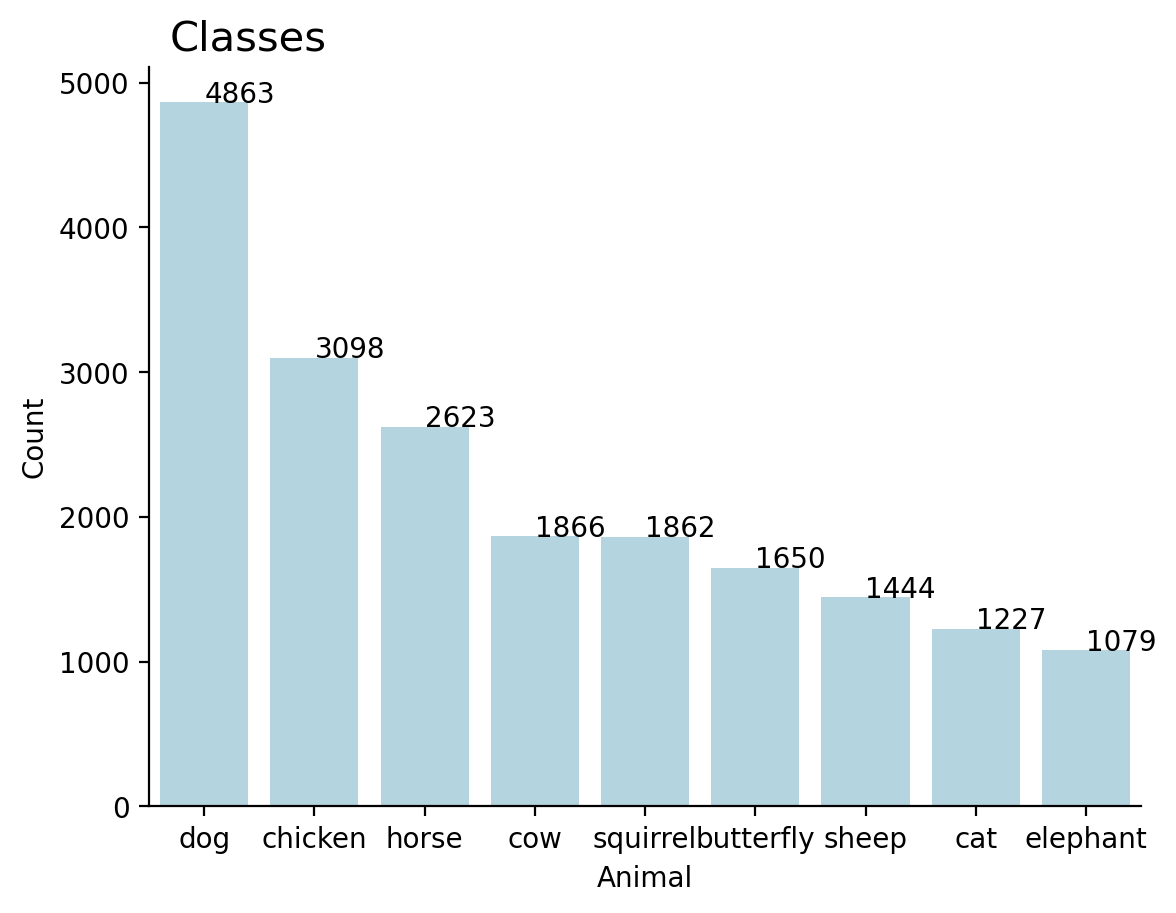

In [10]:
### Barchart with animals

plot = sns.countplot(x = df_data['label'], color='lightblue', order = df_data['label'].value_counts().index)
sns.despine()
plot.set_title('Classes', x=0.1, y=1, fontsize=15)
plot.set_ylabel('Count', x=0.02)
plot.set_xlabel('Animal')

for p in plot.patches:
    plot.annotate(format(p.get_height(), '.0f'), (p.get_x() + p.get_width() / 2, p.get_height()))

## Instantiating model 

In [11]:
model = models.resnet18(pretrained=True)

In [12]:
T = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

## TRAIN & TEST LOADER

In [13]:
from torch.utils.data import random_split, DataLoader, Dataset
from torchvision.datasets import ImageFolder

dataset = ImageFolder('archive/raw-img', transform=T)


train_set, val_set = random_split(dataset, [int(len(dataset)*.8), len(dataset) - int(len(dataset)*.8)])
train_loader = DataLoader(train_set, batch_size=64)
test_loader = DataLoader(val_set, batch_size=64)

## Model

In [14]:
model.fc = nn.Linear(512, 10)

In [15]:
model = model
if torch.cuda.is_available():
    model = model.cuda()
    
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

In [16]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(torch.cuda.is_available())
model.to(device)

False


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

## Training and Testing

In [18]:
from tqdm import tqdm

epochs = 25
train_losses, test_losses = [], []

for epoch in range(epochs):
    loss = 0.0
    accuracy = 0.0
    train_loss = 0.0
    test_loss = 0.0
    total = 0.0
    correct = 0.0
    
    model.train()
    
    for i, (images, labels) in tqdm(enumerate(train_loader)):
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        output = model(images)
        
        loss = criterion(output, labels)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
        _, predicted = output.max(dim=1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
    
    train_accuracy = 100 * correct / total
    print(f'Training Loss: {train_loss / len(train_loader):.3f},'
          f'Training Accuracy: {train_accuracy:.2f}%')
    
    model.eval()
    
    with torch.no_grad():
        
        for i, (images, labels) in tqdm(enumerate(test_loader)):
            images, labels = images.to(device), labels.to(device)
            
            log_ps = model(images)
            loss = criterion(log_ps, labels)
            test_loss += loss.item()
            
            ps = torch.exp(log_ps)
            top_p, top_class = ps.topk(1, dim=1)
            equals = top_class == labels.view(*top_class.shape)
            accuracy += torch.mean(equals.type(torch.FloatTensor))

    train_losses.append(train_loss / len(train_loader))
    test_losses.append(test_loss / len(test_loader))
    
    model.train()
    print("Epoch: {}/{}.. ".format(epoch+1, epochs),
          "Training Loss: {:.3f}.. ".format(train_loss/len(train_loader)),
          "Test Loss: {:.3f}.. ".format(test_loss/len(test_loader)),
          "Test Accuracy: {:.3f}".format(accuracy/len(test_loader)))

KeyboardInterrupt: 

In [15]:
model_state = {
    'state_dict': model.state_dict(),
    'optimizer': optimizer.state_dict(),
}
torch.save(model_state, 'ANIMAL_MODEL_FINISHED.pth')

In [19]:
import warnings
import math
warnings.filterwarnings('ignore')

Accuracy on 50 images: 95.56%


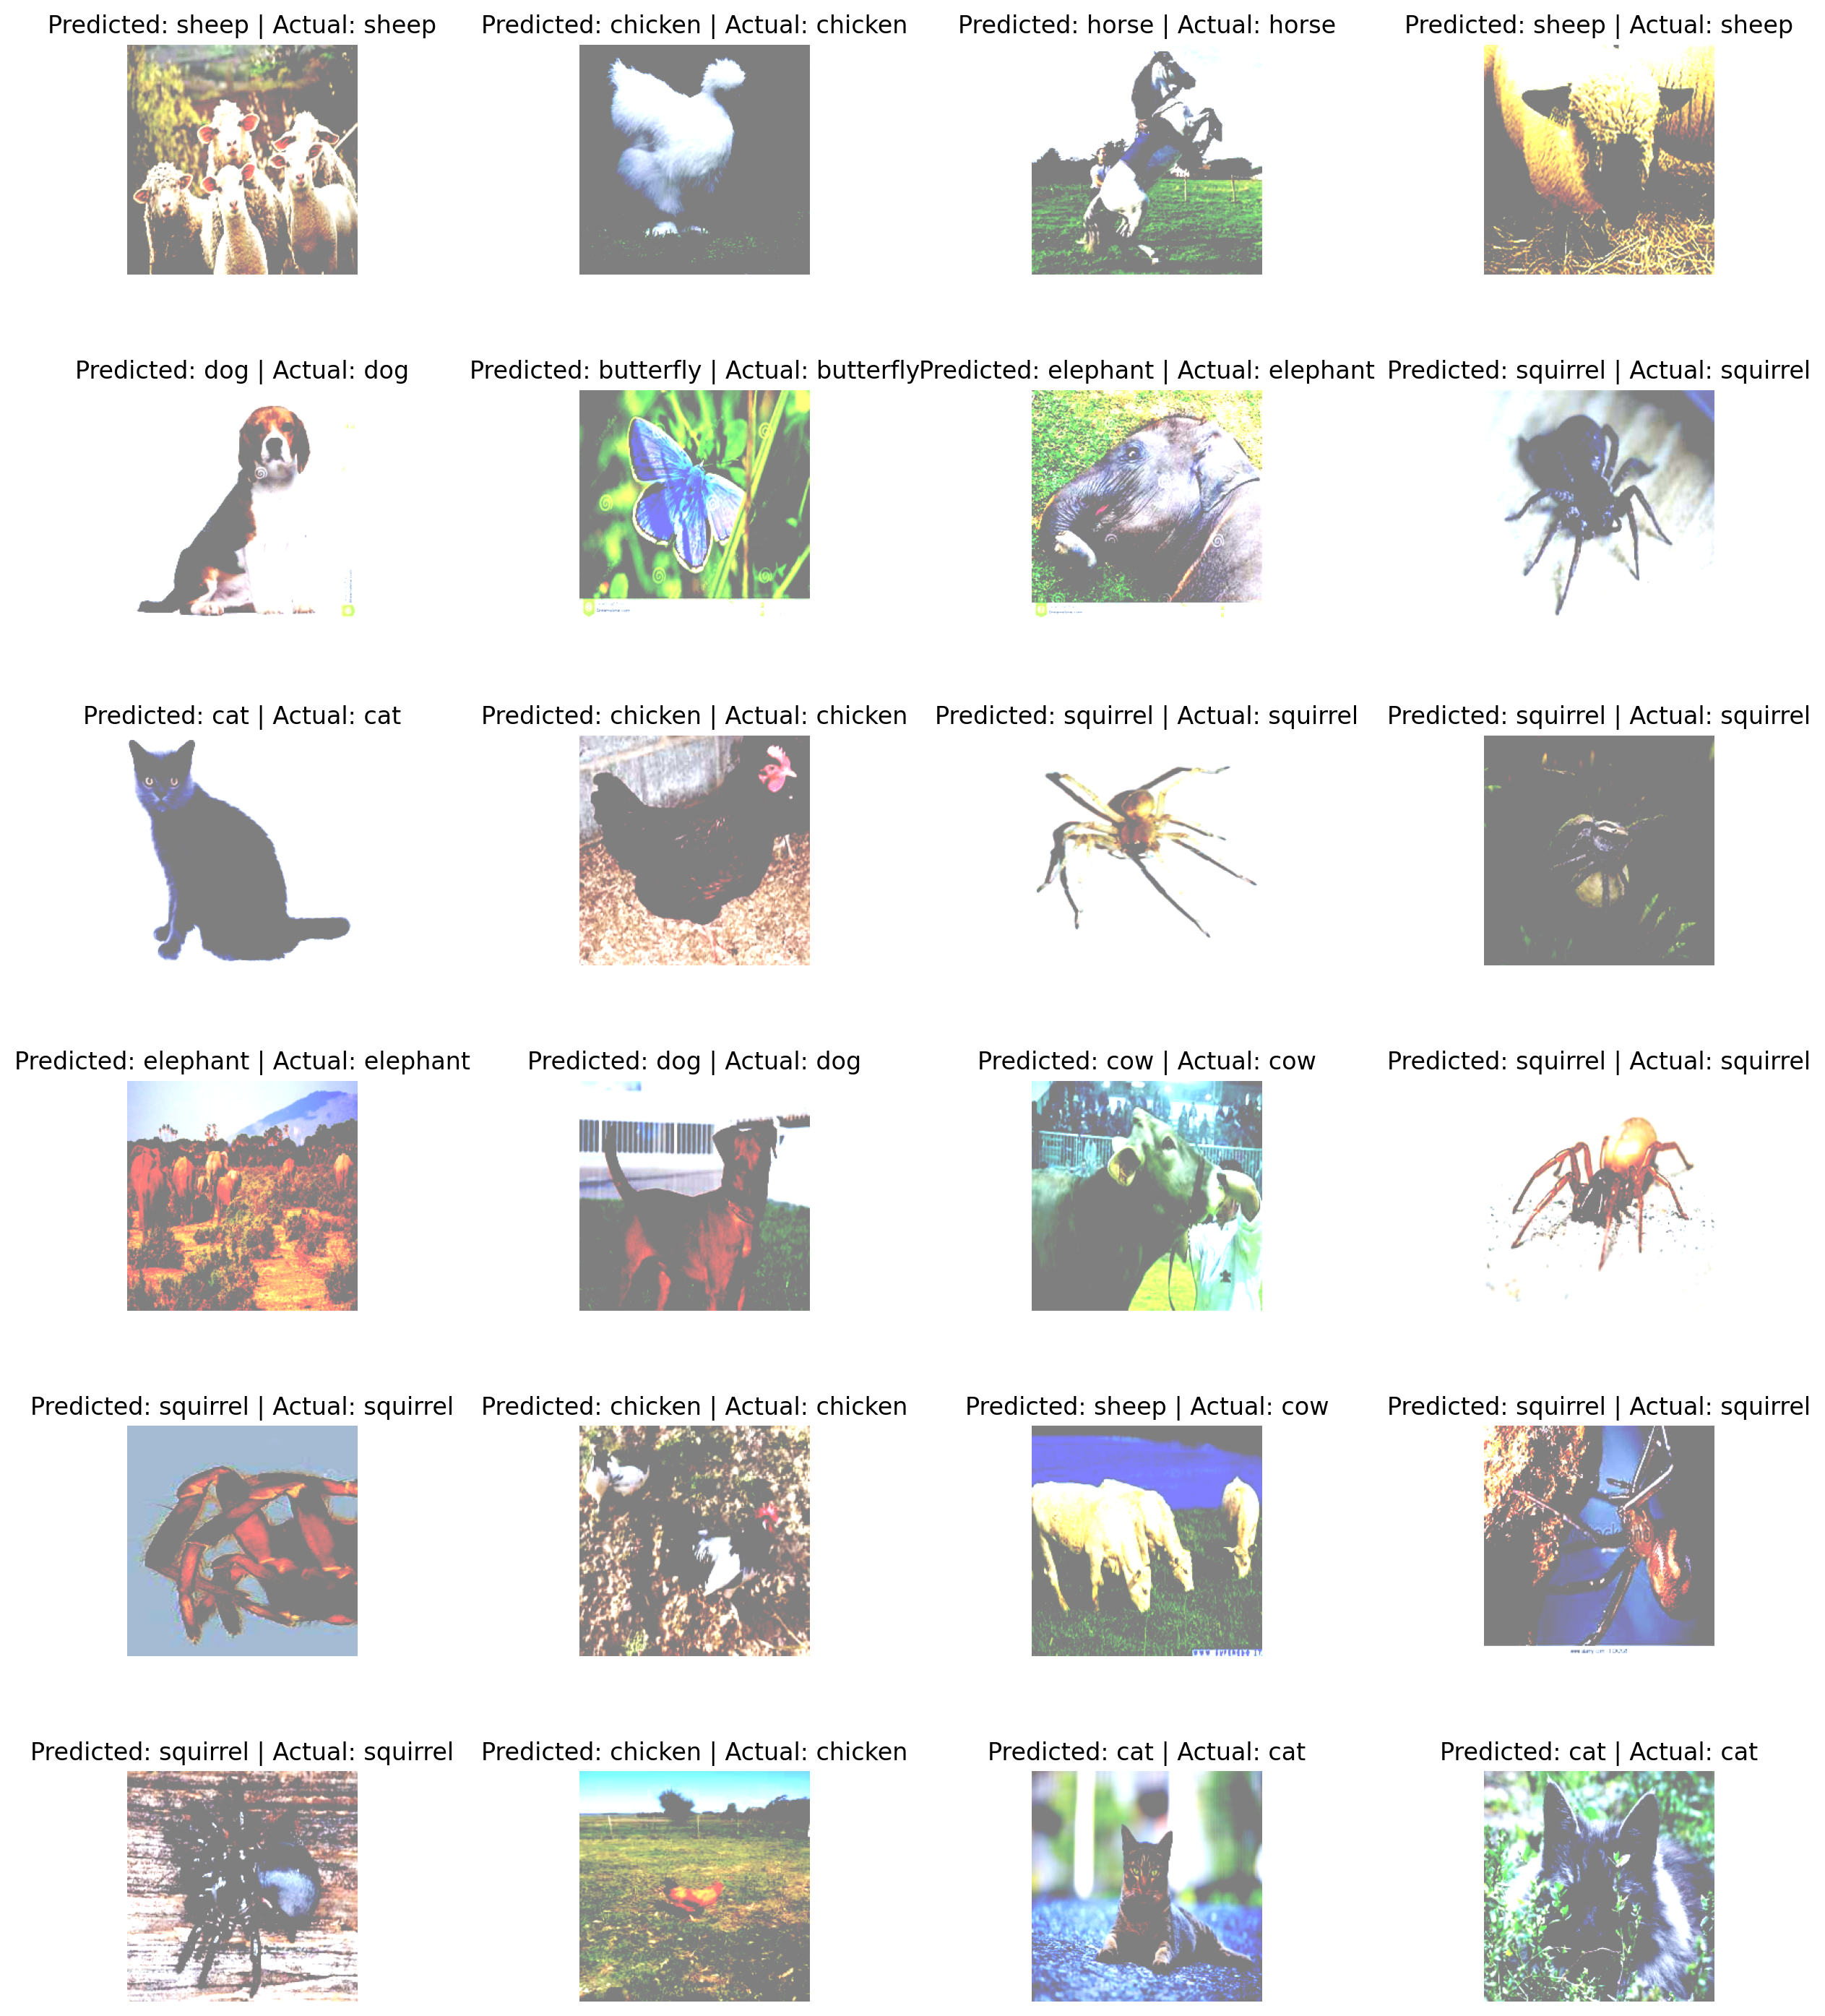

In [72]:
# Choose a subset of the testing dataset
num_images_to_show = 50
subset_indices = range(num_images_to_show)

# Calculate accuracy
correct = 0
total = 0

# Load Model 
model = models.resnet18(pretrained=True)
model.fc = torch.nn.Linear(512, 10)
# Load the saved model checkpoint
checkpoint = torch.load('ANIMAL_MODEL_FINISHED.pth', map_location=torch.device('cpu'))  # Replace with the path to your saved checkpoint
model.load_state_dict(checkpoint['state_dict'])

# Classes
classes = ["dog", 
           "horse", 
           "elephant", 
           "butterfly", 
           "chicken", 
           "cat", 
           "cow", 
           "sheep", 
           "squirrel", 
           "cane", 
           "horse", 
           "elefante",
           "farfalla", 
           "gallina", 
           "gatto",
           "mucca",
           "ragno",
           "scoiattolo"]

with torch.no_grad():
    for i, (images, labels) in tqdm(enumerate(test_loader)):
        if i >= 25:
            break
            
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

# Print accuracy
print(f'Accuracy on {num_images_to_show} images: {accuracy:.2f}%')


# Set the model to evaluation mode
model.eval()

# Make predictions and plot images with predicted labels
plt.figure(figsize=(15, 30))
for i, (image, label) in tqdm(enumerate(test_loader, 1)):
    if i >= 25:
        break
        
    with torch.no_grad():
        output = model(image)
        _, predicted = torch.max(output, 1)
        
        plt.subplot(10, 4, i)
        # Ensure pixel values are in the [0, 1] range
        image = torch.clamp(image, 0, 1)
        plt.imshow((image[0] * 0.5 + 0.5).permute(1, 2, 0))
        plt.title(f'Predicted: {classes[predicted[0]]} | Actual: {classes[label[0]]}')
        plt.axis('off')
    
        if i >= num_images_to_show:
            break

plt.subplots_adjust(wspace=0.4, hspace=0.5)
plt.show()